# 02 · All signals on one clock

A SensorForge log of two sensors worn together: a **Polar H10** chest strap (ECG 130 Hz, acceleration 200 Hz, heart rate, RR intervals) and a **Polar Verity Sense** on the upper arm (PPG 55 Hz, acceleration and gyroscope 52 Hz, magnetometer 100 Hz, PP intervals). 30 minutes of a science-centre visit, with a *Lunch* marker.

1. every stream on one shared, zoomable time axis
2. eight seconds of every raw channel
3. ECG-triggered PPG average: how long the pulse wave takes from the heart to the arm

**Zooming:** with ipympl installed every figure has a toolbar: the magnifier zooms into a box, the cross pans, the house resets. Long signals are drawn as min/max envelopes and refine down to the raw samples as you zoom; spectrograms are recomputed at a finer time resolution. Panels that share a time axis zoom together.

In [1]:
# Google Colab: fetch the repository (data + helpers) first. Elsewhere this cell does nothing.
import sys
if "google.colab" in sys.modules:
    !git clone -q --depth 1 https://github.com/Nsantis/sensorforge-examples /content/sensorforge-examples
    %cd /content/sensorforge-examples/notebooks
    !pip -q install ipympl
    from google.colab import output
    output.enable_custom_widget_manager()

In [2]:
from sfutils import *
setup_plots()   # zoomable figures with ipympl; static ones without it (or with SF_STATIC=1)

LOG = "../data/SF_20261031-105000_day-out-30min"
S = load_session(LOG)
print(S.manifest["startedAt"], "→", S.manifest["endedAt"], f"({S.end_s / 60:.0f} min, {S.tz})")
for (dev, sig), df in S.streams.items():
    if dev:
        print(f"  {S.name(dev):32s} {sig:5s} {len(df):>9,} rows")

2026-10-31T08:50:00.000Z → 2026-10-31T09:20:00.000Z (30 min, Europe/Helsinki)
  H10 971A3624 (chest)             hr        1,800 rows
  H10 971A3624 (chest)             rr        2,309 rows
  Sense 89672C22 (upper arm left)  ppg      98,639 rows
  Sense 89672C22 (upper arm left)  acc      95,725 rows
  Sense 89672C22 (upper arm left)  mag     182,545 rows
  Sense 89672C22 (upper arm left)  gyro     95,766 rows
  H10 971A3624 (chest)             acc     362,124 rows
  H10 971A3624 (chest)             ecg     234,403 rows
  Sense 89672C22 (upper arm left)  ppi       1,853 rows


## Streams

Nominal rate and settings come from `session.json` (what the sensor agreed to); the measured rate from the sensor's own timestamps.

In [3]:
rows = []
for meta in S.manifest["streams"]:
    df = S.streams.get((meta.get("deviceId"), meta["signal"]))
    if df is None or meta["signal"] == "markers":
        continue
    row = {"device": S.name(meta["deviceId"]), "signal": meta["signal"], "rows": len(df), "unit": meta.get("unit"),
           "settings": ", ".join(f"{k}={v}" for k, v in meta.get("settings", {}).items())}
    if "sensor_ts_ns" in df and (df["sensor_ts_ns"] != 0).any():
        row["measured Hz"] = round(1e9 / np.median(np.diff(df["sensor_ts_ns"].to_numpy())), 2)
    rows.append(row)
pd.DataFrame(rows)

,device,signal,rows,unit,settings,measured Hz
0,H10 971A3624 (chest),hr,1800,bpm,,NaN
1,H10 971A3624 (chest),rr,2309,ms,,NaN
2,Sense 89672C22 (upper arm left),ppg,98639,ADC,"channels=4, frameType=ppg3_ambient1, resolutio...",54.80
3,Sense 89672C22 (upper arm left),acc,95725,mG,"channels=3, range=8, resolution=16, sampleRate=52",53.18
4,Sense 89672C22 (upper arm left),mag,182545,G,"channels=3, range=50, resolution=16, sampleRat...",101.41
5,Sense 89672C22 (upper arm left),gyro,95766,°/s,"channels=3, range=2000, resolution=16, sampleR...",53.18
6,H10 971A3624 (chest),acc,362124,mG,"range=8, resolution=16, sampleRate=200",201.17
7,H10 971A3624 (chest),ecg,234403,µV,"resolution=14, sampleRate=130",130.21
8,Sense 89672C22 (upper arm left),ppi,1853,ms,,NaN


## Everything on one time axis

Vector magnitudes for the 3-axis sensors, the raw mean of the three PPG channels (slow drift from contact pressure and blood volume; the pulses appear when you zoom in), beat-to-beat intervals as dots. Zoom into any panel: all of them follow, and at a few seconds you see the raw samples (ECG complexes, pulse waves, steps).

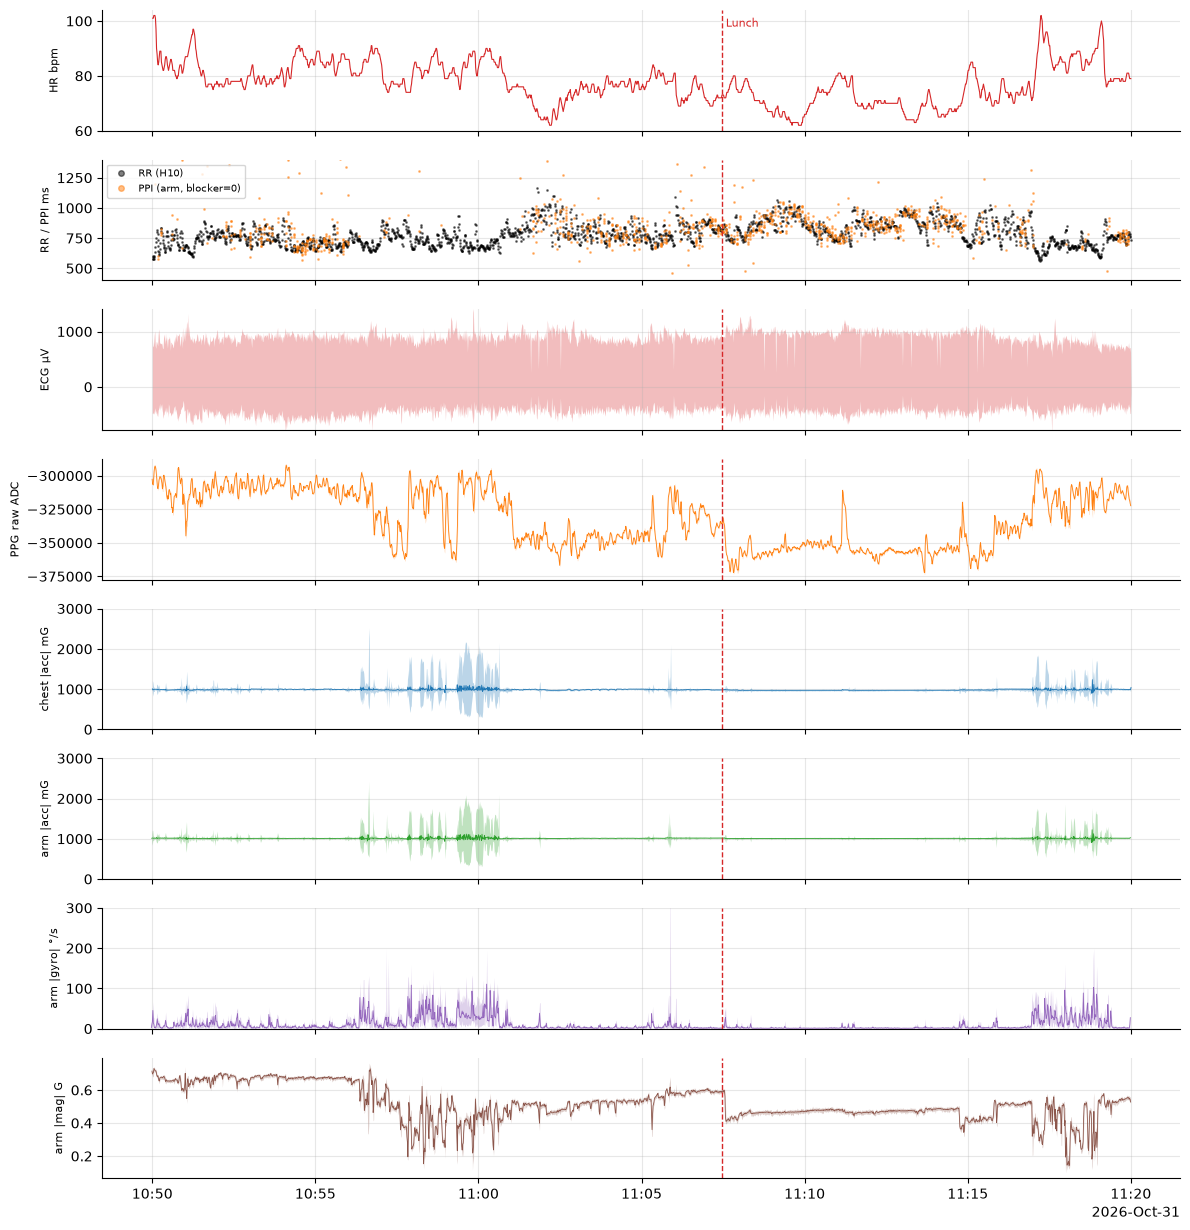

In [4]:
H10, ARM = S.device_of("ecg"), S.device_of("ppg")
for dev, sig, cols, name in [(H10, "acc", ["x_mg", "y_mg", "z_mg"], "mag"), (ARM, "acc", ["x_mg", "y_mg", "z_mg"], "mag"),
                             (ARM, "gyro", ["x_dps", "y_dps", "z_dps"], "mag"), (ARM, "mag", ["x_gauss", "y_gauss", "z_gauss"], "mag")]:
    df = S.get(sig, dev)
    df[name] = np.sqrt(sum(df[c].astype(float) ** 2 for c in cols))
ppg = S.get("ppg")
ppg["ppg_mean"] = ppg[["ch0", "ch1", "ch2"]].mean(axis=1)

hr, rr, ppi = S.get("hr", H10), S.get("rr"), S.get("ppi")
panels = [
    ("HR bpm", lambda ax: ax.plot(hr["t"], hr["hr_bpm"].where(hr["hr_bpm"] > 0), color="C3", lw=0.8)),
    ("RR / PPI ms", lambda ax: (ax.plot(rr["t"], rr["rr_ms"], ".", ms=2, color="k", alpha=0.5, label="RR (H10)"),
                                ax.plot(ppi["t"], ppi["ppi_ms"].where(ppi["blocker"] == 0), ".", ms=2, color="C1",
                                        alpha=0.5, label="PPI (arm, blocker=0)"),
                                ax.legend(fontsize=7, loc="upper left", markerscale=4))),
    ("ECG µV", lambda ax: plot_env(ax, S, S.get("ecg"), "ecg_uv", "C3", line=False)),
    ("PPG raw ADC", lambda ax: plot_env(ax, S, ppg, "ppg_mean", "C1")),
    ("chest |acc| mG", lambda ax: plot_env(ax, S, S.get("acc", H10), "mag", "C0")),
    ("arm |acc| mG", lambda ax: plot_env(ax, S, S.get("acc", ARM), "mag", "C2")),
    ("arm |gyro| °/s", lambda ax: plot_env(ax, S, S.get("gyro", ARM), "mag", "C4")),
    ("arm |mag| G", lambda ax: plot_env(ax, S, S.get("mag", ARM), "mag", "C5")),
]
fig, axes = plt.subplots(len(panels), 1, figsize=(12, 1.55 * len(panels)), sharex=True)
for ax, (label, draw) in zip(axes, panels):
    draw(ax)
    ax.set_ylabel(label, fontsize=8)
    decorate(ax, S, labels=ax is axes[0])
axes[1].set_ylim(400, 1400)
axes[2].set_ylim(*np.percentile(S.get("ecg")["ecg_uv"], [0.05, 99.95]) * 1.3)
axes[4].set_ylim(0, 3000); axes[5].set_ylim(0, 3000); axes[6].set_ylim(0, 300)
time_axis(axes[-1]); plt.tight_layout(); plt.show()

## Eight seconds of every raw channel

All three axes of every motion sensor, the ECG and the band-passed PPG. The grey vertical lines are ECG R peaks: each heartbeat shows up a moment later as a pulse wave in the arm's PPG. Change `AT` (local time) to look elsewhere.

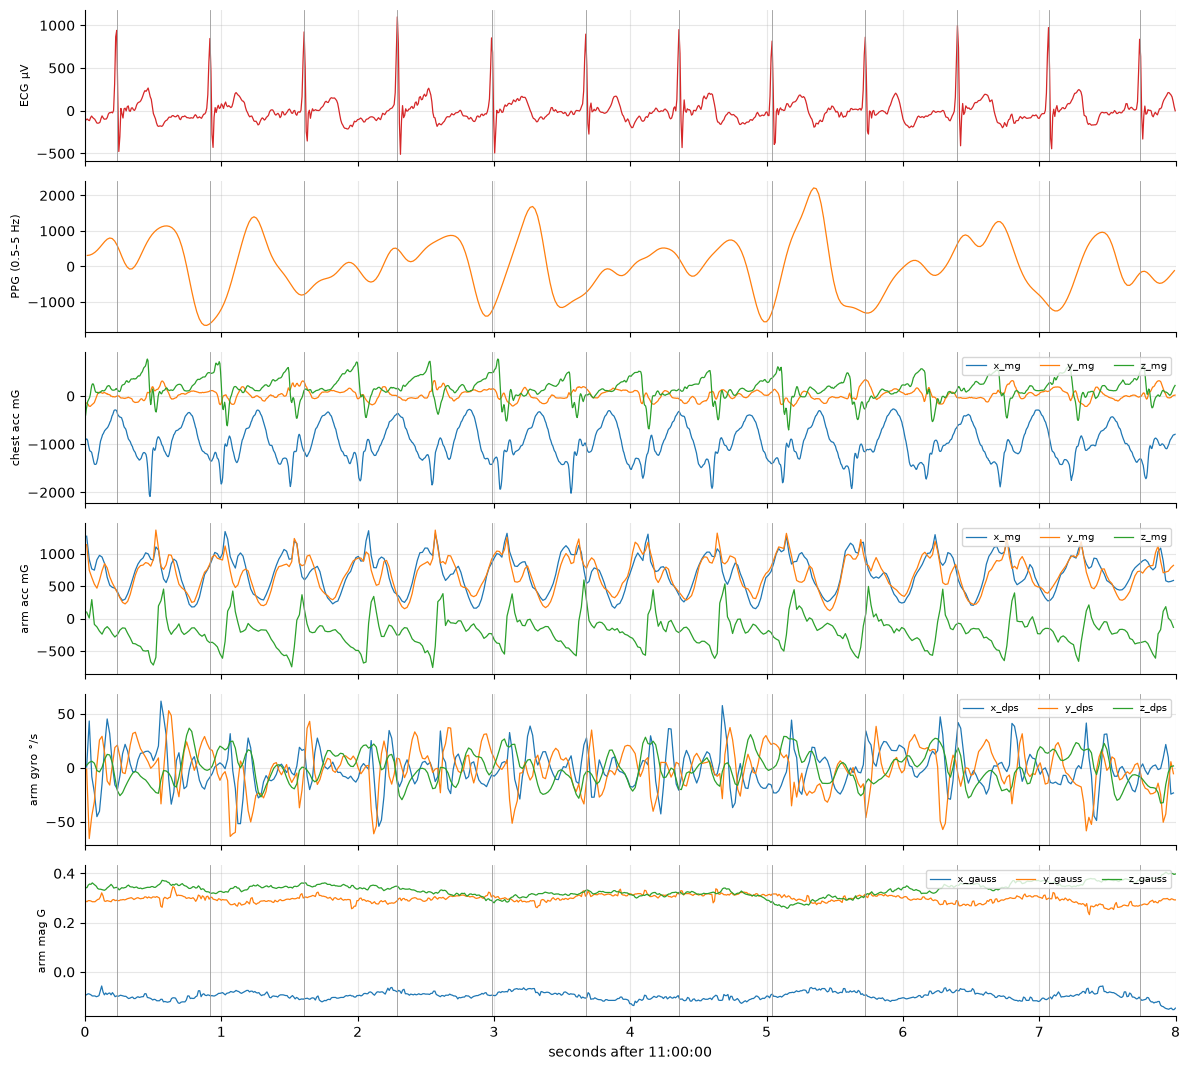

In [5]:
AT, LENGTH_S = "11:00:00", 8.0
a = S.at(AT)

def win(df, pad=0.0):
    return df[(df["elapsed_s"] >= a - pad) & (df["elapsed_s"] < a + LENGTH_S + pad)]

fs_ppg = 1e9 / np.median(np.diff(ppg["sensor_ts_ns"].to_numpy()))
w_ppg = win(ppg, pad=10)
w_ppg = win(w_ppg.assign(ppg_f=bandpass(w_ppg["ppg_mean"].to_numpy(float), fs_ppg, 0.5, 5.0)))
R = detect_r_peaks(S.get("ecg"))

xyz = lambda sig, dev, cols: [(win(S.get(sig, dev)), c) for c in cols]
panels = [("ECG µV", [(win(S.get("ecg")), "ecg_uv")]), ("PPG (0.5–5 Hz)", [(w_ppg, "ppg_f")]),
          ("chest acc mG", xyz("acc", H10, ["x_mg", "y_mg", "z_mg"])), ("arm acc mG", xyz("acc", ARM, ["x_mg", "y_mg", "z_mg"])),
          ("arm gyro °/s", xyz("gyro", ARM, ["x_dps", "y_dps", "z_dps"])), ("arm mag G", xyz("mag", ARM, ["x_gauss", "y_gauss", "z_gauss"]))]
fig, axes = plt.subplots(len(panels), 1, figsize=(12, 1.8 * len(panels)), sharex=True)
for ax, (label, series) in zip(axes, panels):
    colors = ["C3"] if label.startswith("ECG") else ["C1"] if label.startswith("PPG") else ["C0", "C1", "C2"]
    for (df, col), color in zip(series, colors):
        ax.plot(df["elapsed_s"] - a, df[col], lw=0.9, color=color, label=col if len(series) > 1 else None)
    for r in R[(R >= a) & (R < a + LENGTH_S)]:
        ax.axvline(r - a, color="0.6", lw=0.6)
    ax.set_ylabel(label, fontsize=8)
    if len(series) > 1:
        ax.legend(fontsize=7, loc="upper right", ncol=3)
axes[-1].set_xlim(0, LENGTH_S); axes[-1].set_xlabel(f"seconds after {AT}")
plt.tight_layout(); plt.show()

## From heart to arm: ECG-triggered PPG average

A single PPG beat is noisy, but averaging hundreds of them aligned on the ECG R peak gives a clean pulse waveform. The delay from the R peak to the **foot** of the pulse (start of the upstroke, here by the intersecting-tangent method) is the *pulse arrival time*: the pre-ejection period of the heart plus the travel time of the pressure wave to the upper arm. It is a building block of cuff-less blood-pressure research.

The average also answers a practical question about the raw data: which way is up? The beat rises fast (systole) and decays slowly, so in Polar's raw PPG **larger values mean more blood volume**.

Only beats whose whole window has PPG data and little arm movement are used. Both sensors' timestamps are on the phone clock, so the result also includes any residual clock offset between them (typically tens of milliseconds).

1879 beats averaged · pulse foot 126 ms, systolic peak 439 ms after the R peak


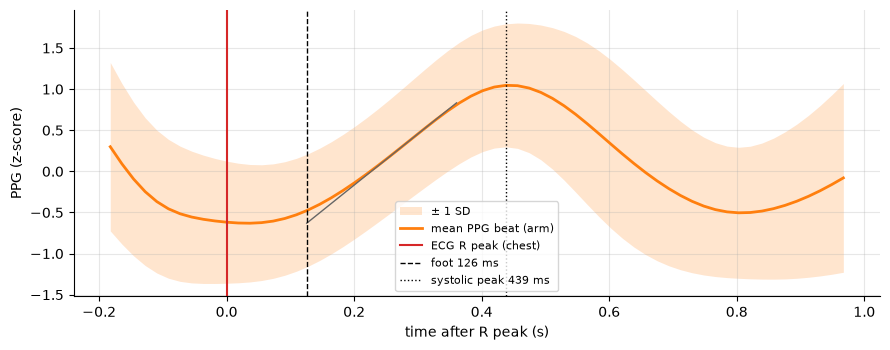

In [6]:
grid = PPGGrid(S, ppg, lo=0.5, hi=8.0)
arm_acc = S.get("acc", ARM)
move = arm_acc.groupby(np.floor(arm_acc["elapsed_s"]))["mag"].std()   # per-second movement

PRE, POST = 0.2, 1.0
n_pre, n_post = int(PRE * grid.fs), int(POST * grid.fs)
beats = []
for r in R:
    i = int(round((r - grid.t0) * grid.fs))
    if i - n_pre < 0 or i + n_post >= len(grid.x) or not grid.valid[i - n_pre:i + n_post].all():
        continue
    if move.get(np.floor(r), np.inf) > 30:    # mG; skip beats during arm movement
        continue
    seg = grid.x[i - n_pre:i + n_post]
    beats.append((seg - seg.mean()) / seg.std())
beats = np.array(beats)
lag = np.arange(-n_pre, n_post) / grid.fs
avg, sd = beats.mean(axis=0), beats.std(axis=0)

# 1 ms resolution; foot = where the tangent at the steepest upstroke crosses the preceding minimum
fine = np.arange(lag[0], lag[-1], 0.001)
y = np.interp(fine, lag, avg)
peak = np.flatnonzero((fine > 0.1) & (fine < 0.7)); peak = peak[np.argmax(y[peak])]
trough = np.flatnonzero((fine > -0.1) & (fine < fine[peak])); trough = trough[np.argmin(y[trough])]
slope = np.gradient(y, fine)
up = np.arange(trough, peak); up = up[np.argmax(slope[up])]
foot_s = fine[up] - (y[up] - y[trough]) / slope[up]
peak_s = fine[peak]
print(f"{len(beats)} beats averaged · pulse foot {1000 * foot_s:.0f} ms, systolic peak {1000 * peak_s:.0f} ms after the R peak")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.fill_between(lag, avg - sd, avg + sd, color="C1", alpha=0.2, lw=0, label="± 1 SD")
ax.plot(lag, avg, color="C1", lw=2, label="mean PPG beat (arm)")
ax.axvline(0, color="C3", lw=1.5, label="ECG R peak (chest)")
ax.plot([fine[up] - (y[up] - y[trough]) / slope[up], fine[up] + 0.08], [y[trough], y[up] + 0.08 * slope[up]],
        color="0.4", lw=1)   # tangent
ax.axvline(foot_s, color="k", ls="--", lw=1, label=f"foot {1000 * foot_s:.0f} ms")
ax.axvline(peak_s, color="k", ls=":", lw=1, label=f"systolic peak {1000 * peak_s:.0f} ms")
ax.set_xlabel("time after R peak (s)"); ax.set_ylabel("PPG (z-score)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()